# Quadro-síntese: o CBIS-DDSM representa o Brasil?

**Pergunta principal:** em que medida as características dos casos do CBIS-DDSM são compatíveis com o perfil
epidemiológico do câncer de mama no Brasil?

Este notebook reúne, em um só lugar, as comparações feitas nos notebooks 01, 02 e 03: para cada dimensão, o valor
no CBIS-DDSM, o valor no Brasil, o tamanho da diferença e um veredito. Os números são recalculados a partir de
`dashboards/dados/` (gerado por `python -m src.visualization.painel_dados` depois do notebook 03) e de
`data/interim/`.

In [1]:
import json
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from matplotlib.patches import FancyBboxPatch

from src import config
from src.visualization import estilo
from src.visualization.estilo import AZUL, VERDE_AGUA, salvar

estilo.aplicar()

D = config.ROOT / "dashboards" / "dados"
ler = lambda nome: pd.read_csv(D / f"{nome}.csv", encoding="utf-8-sig")
ind = json.loads((D / "indicadores.json").read_text(encoding="utf-8"))
dens = ler("comparacao_densidade").pivot_table(index="fonte", columns="densidade", values="percentual")
birads = ler("comparacao_birads").pivot_table(index="fonte", columns="birads", values="percentual")
dens_faixa = ler("densidade_faixa")
auc = ler("modelo_auc_populacao").set_index("populacao")
fato = ler("fato_uf_ano").merge(ler("dim_localidade"), on="localidade")
incid_uf = ler("fato_incidencia_uf").merge(ler("dim_localidade"), on="localidade")
inca_mamo = pd.read_csv(config.INTERIM / "inca_mamografias_sus.csv")
inca_inc = pd.read_csv(config.INTERIM / "inca_incidencia.csv")


def br(x, casas=0):
    return f"{x:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")

## 1. Os números de cada dimensão

In [2]:
m = {}

# densidade mamária
m["dist_br"] = dens.loc["Brasil (SISCAN)"]
m["dist_cbis"] = dens.loc["CBIS-DDSM"]
m["densas_br"] = m["dist_br"][[3, 4]].sum()
m["densas_cbis"] = m["dist_cbis"][[3, 4]].sum()
m["w"] = ind["w_cohen_densidade"]

# tipo de caso e proporção de câncer
m["susp_rastr"] = birads.loc["Brasil: rastreamento", [4, 5]].sum()
m["susp_diag"] = birads.loc["Brasil: diagnóstica", [4, 5]].sum()
m["susp_cbis"] = birads.loc["CBIS-DDSM", [4, 5]].sum()
m["malig_cbis"] = ind["cbis_pct_malignas"]
m["casos_100_br"] = ind["brasil_casos_por_100_mamografias"]
robustez = pd.read_csv(config.PROCESSED / "robustez_case_mix.csv", index_col=0)
m["razao_min"], m["razao_max"] = robustez["razão CBIS / Brasil"].min(), robustez["razão CBIS / Brasil"].max()

# idade: densidade por faixa etária no Brasil e a idade "equivalente" ao CBIS-DDSM
pct_densas = (dens_faixa.assign(densa=dens_faixa["densidade"] >= 3)
              .groupby(["ordem_faixa", "faixa_etaria"])
              .apply(lambda g: 100 * g.loc[g["densa"], "exames"].sum() / g["exames"].sum(), include_groups=False)
              .reset_index(level=0, drop=True))
adultas = pct_densas.loc["40–44":"75–79"]
m["densas_40_44"], m["densas_65_69"] = pct_densas["40–44"], pct_densas["65–69"]
m["faixa_equivalente"] = (adultas - m["densas_cbis"]).abs().idxmin()
rastr_faixa = (inca_mamo.query("tabela == 3 and nivel == 'regiao'")
               .groupby("faixa_etaria")["valor"].sum())
m["rastr_40_49"] = 100 * rastr_faixa["40 a 49 anos"] / rastr_faixa.sum()

# região: incidência e cobertura do rastreamento
taxa_reg = inca_inc.query("nivel == 'regiao' and indicador == 'taxa_ajustada_100mil'").set_index("localidade")["valor"]
m["inc_min"], m["inc_max"] = taxa_reg.min(), taxa_reg.max()
m["inc_min_reg"], m["inc_max_reg"] = taxa_reg.idxmin(), taxa_reg.idxmax()
mulheres = (incid_uf["casos_estimados"] / incid_uf["taxa_bruta_100mil"] * 1e5).groupby(incid_uf["regiao"]).sum()
rastr_22 = fato.query("ano == 2022").groupby("regiao")["mamografias_rastreamento"].sum()
cobertura = 1000 * rastr_22 / mulheres
m["cob_min"], m["cob_max"] = cobertura.min(), cobertura.max()
m["cob_min_reg"], m["cob_max_reg"] = cobertura.idxmin(), cobertura.idxmax()

# região: SISCAN por UF (notebook 03)
sis_reg = pd.read_csv(config.PROCESSED / "siscan_regiao.csv", index_col="regiao")
m["densas_se"], m["densas_n"] = sis_reg.loc["Sudeste", "% mamas densas"], sis_reg.loc["Norte", "% mamas densas"]
m["w_se"], m["w_n"] = sis_reg.loc["Sudeste", "w CBIS-DDSM × região"], sis_reg.loc["Norte", "w CBIS-DDSM × região"]
m["auc_n"] = sis_reg.loc["Norte", "AUC"]

# modelo
m["auc_cbis"] = auc.loc["CBIS-DDSM (teste, sem peso)", "auc"]
m["auc_br"] = auc.loc["Brasil, todas as idades", "auc"]
m["auc_40_49"] = auc.loc["Brasil, 40–49", "auc"]
m["auc_70"] = auc.loc["Brasil, 70+", "auc"]

pd.Series({k: v for k, v in m.items() if not isinstance(v, pd.Series)}).to_frame("valor")

,valor
densas_br,50.205489
densas_cbis,46.466629
w,0.096896
susp_rastr,0.892234
susp_diag,5.123664
susp_cbis,61.827354
malig_cbis,40.835202
casos_100_br,1.731416
razao_min,12.602766
razao_max,38.684321


## 2. Quadro-síntese

Vereditos:

- **Compatível:** a distribuição no CBIS-DDSM é parecida com a brasileira;
- **Incompatível:** a diferença é grande demais para ser ignorada;
- **Depende do subgrupo:** parecido na média, diferente em grupos específicos;
- **Não verificável:** o CBIS-DDSM não tem a informação.

In [3]:
def pct_dist(s):
    return "/".join(br(v) for v in s[[1, 2, 3, 4]]) + "%"

quadro = pd.DataFrame([
    {"Dimensão": "Densidade mamária",
     "CBIS-DDSM": f"{br(m['densas_cbis'])}% densas\n({pct_dist(m['dist_cbis'])})",
     "Brasil": f"{br(m['densas_br'])}% densas\n({pct_dist(m['dist_br'])})",
     "Diferença": f"w de Cohen = {br(m['w'], 2)}\n(diferença pequena)",
     "Veredito": "Compatível"},
    {"Dimensão": "Tipo de caso\n(BI-RADS 4–5)",
     "CBIS-DDSM": f"{br(m['susp_cbis'])}% suspeitos",
     "Brasil": f"{br(m['susp_rastr'], 1)}% no rastreamento\n{br(m['susp_diag'], 1)}% na diagnóstica",
     "Diferença": f"~{br(m['susp_cbis'] / m['susp_rastr'])}× mais suspeitos\nque o rastreamento",
     "Veredito": "Incompatível"},
    {"Dimensão": "Proporção de câncer",
     "CBIS-DDSM": f"{br(m['malig_cbis'])}% das lesões\nsão malignas",
     "Brasil": f"~{br(m['casos_100_br'], 1)} caso novo por\n100 mamografias (SUS)",
     "Diferença": f"~{br(m['malig_cbis'] / m['casos_100_br'])}× mais câncer\n"
                  f"({br(m['razao_min'])}× a {br(m['razao_max'])}× nos cenários)",
     "Veredito": "Incompatível"},
    {"Dimensão": "Idade",
     "CBIS-DDSM": "ausente\n(campo vazio nos DICOMs)",
     "Brasil": f"densas: {br(m['densas_40_44'])}% (40–44)\n→ {br(m['densas_65_69'])}% (65–69)",
     "Diferença": f"CBIS ≈ brasileira de {m['faixa_equivalente']};\n"
                  f"{br(m['rastr_40_49'])}% do rastreamento é 40–49",
     "Veredito": "Não verificável"},
    {"Dimensão": "Região\n(densidade)",
     "CBIS-DDSM": "EUA, sem\ninformação de local",
     "Brasil": f"densas: {br(m['densas_se'])}% (Sudeste)\na {br(m['densas_n'])}% (Norte)",
     "Diferença": f"w = {br(m['w_se'], 2)} com o Sudeste,\n{br(m['w_n'], 2)} com o Norte (AUC {br(m['auc_n'], 2)})",
     "Veredito": "Depende do subgrupo"},
    {"Dimensão": "Desempenho do\nmodelo (AUC)",
     "CBIS-DDSM": f"{br(m['auc_cbis'], 2)} (teste)",
     "Brasil": f"{br(m['auc_br'], 2)} (todas as idades)\n{br(m['auc_40_49'], 2)} (40–49) a {br(m['auc_70'], 2)} (70+)",
     "Diferença": "pior nas mais jovens\n(intervalos se sobrepõem)",
     "Veredito": "Depende do subgrupo"},
])
quadro.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left"}).hide(axis="index")

Dimensão,CBIS-DDSM,Brasil,Diferença,Veredito
Densidade mamária,46% densas (15/39/31/16%),50% densas (16/34/34/16%),"w de Cohen = 0,10 (diferença pequena)",Compatível
Tipo de caso (BI-RADS 4–5),62% suspeitos,"0,9% no rastreamento 5,1% na diagnóstica",~69× mais suspeitos que o rastreamento,Incompatível
Proporção de câncer,41% das lesões são malignas,"~1,7 caso novo por 100 mamografias (SUS)",~24× mais câncer (13× a 39× nos cenários),Incompatível
Idade,ausente (campo vazio nos DICOMs),densas: 68% (40–44) → 35% (65–69),CBIS ≈ brasileira de 55–59; 27% do rastreamento é 40–49,Não verificável
Região (densidade),"EUA, sem informação de local",densas: 47% (Sudeste) a 65% (Norte),"w = 0,06 com o Sudeste, 0,43 com o Norte (AUC 0,73)",Depende do subgrupo
Desempenho do modelo (AUC),"0,74 (teste)","0,76 (todas as idades) 0,73 (40–49) a 0,81 (70+)",pior nas mais jovens (intervalos se sobrepõem),Depende do subgrupo


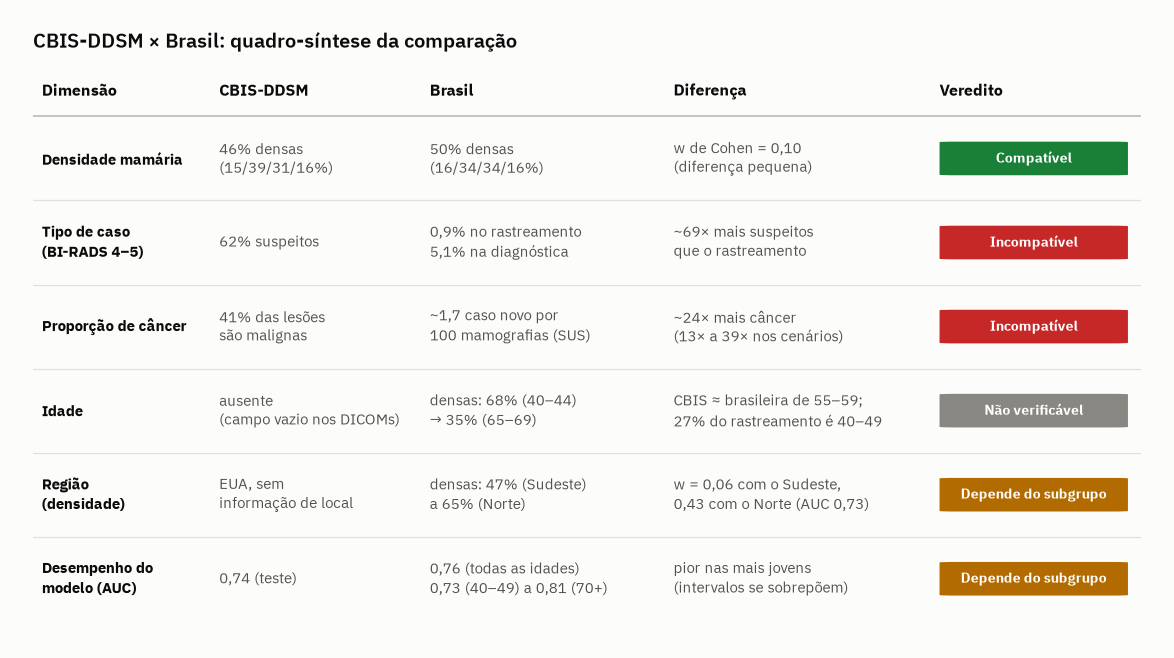

In [4]:
COR_VEREDITO = {"Compatível": "#1a7f37", "Incompatível": "#c62828",
                "Depende do subgrupo": "#b26b00", "Não verificável": estilo.TINTA_SUAVE}
colunas = ["Dimensão", "CBIS-DDSM", "Brasil", "Diferença", "Veredito"]
larguras = [0.16, 0.19, 0.22, 0.24, 0.19]
x0 = [sum(larguras[:i]) for i in range(len(larguras))]
altura_linha, altura_cab = 1.0, 0.6

fig, ax = plt.subplots(figsize=(13, 6.6))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(-(len(quadro) * altura_linha) - 0.05, altura_cab)
for x, col in zip(x0, colunas):
    ax.text(x + 0.008, altura_cab / 2, col, fontweight="bold", va="center", fontsize=10.5, color=estilo.TINTA)
ax.axhline(0, color=estilo.EIXO, lw=1.2)
for i, linha in quadro.iterrows():
    y = -(i + 0.5) * altura_linha
    if i:
        ax.axhline(-i * altura_linha, color=estilo.GRADE, lw=0.8)
    for x, col in zip(x0[:-1], colunas[:-1]):
        ax.text(x + 0.008, y, linha[col], va="center", fontsize=9.5, linespacing=1.35,
                fontweight="bold" if col == "Dimensão" else "normal",
                color=estilo.TINTA if col == "Dimensão" else estilo.TINTA_SECUNDARIA)
    cor = COR_VEREDITO[linha["Veredito"]]
    ax.add_patch(FancyBboxPatch((x0[-1] + 0.008, y - 0.2), larguras[-1] - 0.02, 0.4,
                                boxstyle="round,pad=0,rounding_size=0.015", fc=cor, ec="none",
                                mutation_aspect=0.4))
    ax.text(x0[-1] + larguras[-1] / 2 - 0.002, y, linha["Veredito"], ha="center", va="center",
            fontsize=9, fontweight="bold", color="white")
ax.set_title("CBIS-DDSM × Brasil: quadro-síntese da comparação", fontsize=13, pad=12)
salvar(fig, "23_quadro_sintese")

## 3. As comparações lado a lado

As quatro grandezas que podem ser medidas nas duas bases.

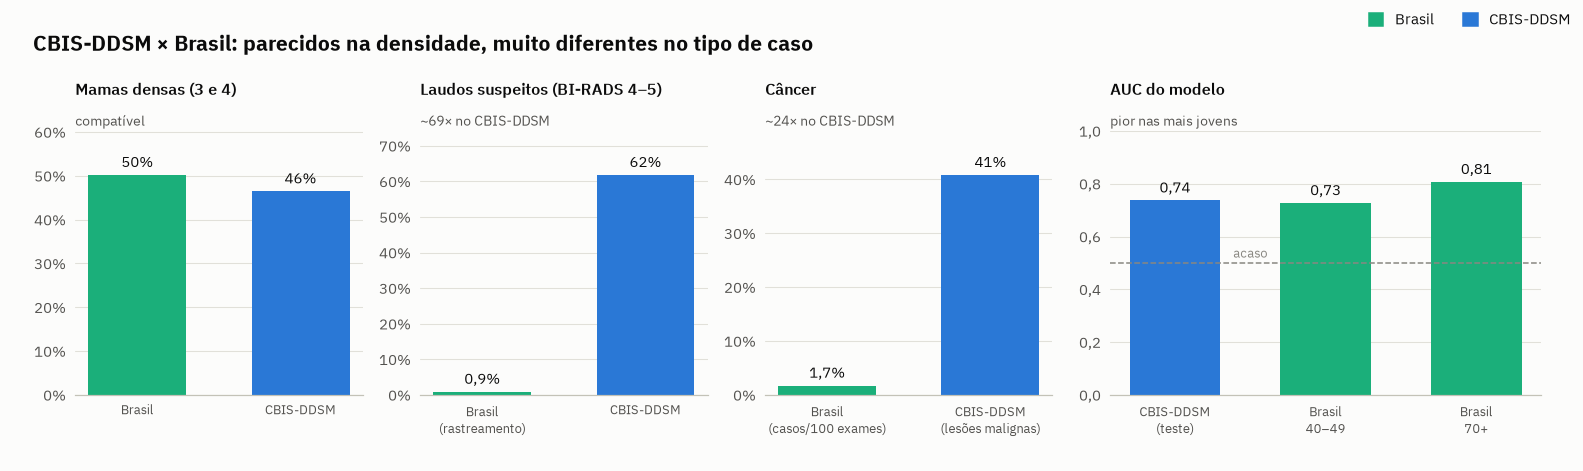

In [5]:
paineis = [
    ("Mamas densas (3 e 4)", "compatível",
     [("Brasil", m["densas_br"]), ("CBIS-DDSM", m["densas_cbis"])], "{}%", 0),
    ("Laudos suspeitos (BI-RADS 4–5)", f"~{br(m['susp_cbis'] / m['susp_rastr'])}× no CBIS-DDSM",
     [("Brasil\n(rastreamento)", m["susp_rastr"]), ("CBIS-DDSM", m["susp_cbis"])], "{}%", 1),
    ("Câncer", f"~{br(m['malig_cbis'] / m['casos_100_br'])}× no CBIS-DDSM",
     [("Brasil\n(casos/100 exames)", m["casos_100_br"]), ("CBIS-DDSM\n(lesões malignas)", m["malig_cbis"])], "{}%", 1),
    ("AUC do modelo", "pior nas mais jovens",
     [("CBIS-DDSM\n(teste)", m["auc_cbis"]), ("Brasil\n40–49", m["auc_40_49"]), ("Brasil\n70+", m["auc_70"])], "{}", 2),
]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.9), gridspec_kw={"width_ratios": [2, 2, 2, 3]})
for ax, (titulo, leitura, barras, fmt, casas) in zip(axes, paineis):
    rotulos = [r for r, _ in barras]
    valores = [v for _, v in barras]
    cores = [AZUL if r.startswith("CBIS") else VERDE_AGUA for r in rotulos]
    b = ax.bar(rotulos, valores, color=cores, width=0.6)
    ax.bar_label(b, labels=[fmt.format(br(v, casas if v < 10 or casas == 2 else 0)) for v in valores],
                 padding=3, color=estilo.TINTA, fontsize=10)
    ax.set_title(f"{titulo}\n", fontsize=10.5)
    ax.text(0, 1.02, leitura, transform=ax.transAxes, fontsize=9, color=estilo.TINTA_SECUNDARIA)
    ax.tick_params(axis="x", labelsize=8.5)
    if titulo.startswith("AUC"):
        ax.set_ylim(0, 1)
        ax.axhline(0.5, color=estilo.TINTA_SUAVE, lw=1, ls="--", zorder=1)
        ax.text(0.5, 0.52, "acaso", ha="center", fontsize=8.5, color=estilo.TINTA_SUAVE)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: br(v, 1)))
    else:
        ax.set_ylim(0, max(valores) * 1.2)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=VERDE_AGUA), plt.Rectangle((0, 0), 1, 1, color=AZUL)],
           labels=["Brasil", "CBIS-DDSM"], loc="upper right", ncol=2, frameon=False)
fig.suptitle("CBIS-DDSM × Brasil: parecidos na densidade, muito diferentes no tipo de caso",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "24_comparacoes_lado_a_lado")

## 4. Resposta à pergunta do trabalho

- **Compatível no que a base mede da mama:** a distribuição de densidade do CBIS-DDSM é praticamente a do
  Brasil (w de Cohen ≈ 0,10).
- **Incompatível no tipo de caso:** o CBIS-DDSM é um conjunto de lesões suspeitas, com dezenas de vezes mais
  laudos BI-RADS 4–5 e mais câncer do que o rastreamento do SUS. Métricas medidas na base (VPP, falsos positivos)
  não se transferem para o rastreamento brasileiro.
- **Não verificável no que mais importa para o viés:** a base não tem idade nem local. No Brasil, a idade
  determina a densidade, e a densidade determina o desempenho do modelo; por isso o desempenho estimado é
  pior justamente nas mulheres de 40 a 49 anos, que fazem cerca de um quarto do rastreamento do SUS.
- **Depende da região:** o CBIS-DDSM se parece com o Sudeste, mas não com o Norte, onde as mamas são bem mais
  densas, mesmo descontando a idade. O Norte já tem a menor cobertura de rastreamento e a maior razão entre óbitos
  e casos, e é onde o modelo teria o pior desempenho estimado.

**Hipótese confirmada em parte:** o CBIS-DDSM se parece com o Brasil na média da densidade, mas não no tipo de caso,
e a média esconde os subgrupos (idade, região) em que a diferença é maior.

Os detalhes e as limitações de cada linha estão nos notebooks de origem: densidade e BI-RADS no 03, proporção de
câncer e regiões no 01, densidade por região no 03, desempenho do modelo no 02 e no 03.